Same as 02 but expanding to hamming codes to be a bit more ambitious now that the sanity is checked with the 3-bit parity experiment

In [29]:
import scipy.integrate as int
import matplotlib.pyplot as plt
import numpy as np

In [30]:
#We are going to define activation functions for feature and memory separately
beta_feature = 1 #Sharpness of the tanh activation
# def f_feature(xvec):
#     return np.tanh(beta_feature*xvec) #Shift and scale to [0,1]
def f_feature(xvec):
    return beta_feature*xvec

beta_memory = 1 #Sharpness of the softmax activation function
def f_memory(x, axis=-1):
    # Subtract max for numerical stability along the specified axis
    x_max = np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(beta_memory*(x - x_max))
    
    # Divide by the sum of exponentials along the same axis
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)



In [31]:
#Binary error correction task, so rows are target code words. 
#nColumns is the number of features, nRows is the number of memories

codewordMatrix = np.asarray([[0,0,0,0,0,0,0],
                             [1,1,1,0,0,0,0],
                             [1,0,0,1,1,0,0],
                             [0,1,1,1,1,0,0],
                             [0,1,0,1,0,1,0],
                             [1,0,1,1,0,1,0],
                             [1,1,0,0,1,1,0],
                             [0,0,1,0,1,1,0],
                             [1,1,0,1,0,0,1],
                             [0,0,1,1,0,0,1],
                             [0,1,0,0,1,0,1],
                             [1,0,1,0,1,0,1],
                             [1,0,0,0,0,1,1],
                             [0,1,1,0,0,1,1],
                             [0,0,0,1,1,1,1],
                             [1,1,1,1,1,1,1]
                             ])*2-1
print(codewordMatrix)
nFeatures = np.shape(codewordMatrix)[1]
nMemories = np.shape(codewordMatrix)[0]

#Construct the array of rhs functions
#NOTE: DEFAULT ARGUMENT TRICK REQUIRED TO BAKE IN CORRECT NUMBERS IN PYTHON
rhs = []
for i in range(nFeatures):
    rhs.append(
        lambda x, ymems, featidx=i: -x + np.dot(np.copy(codewordMatrix[:,featidx]),ymems)
    )
for j in range(nMemories):
    rhs.append(
        lambda x, yfeats, memidx=j: -x + np.dot(np.copy(codewordMatrix[memidx,:]),yfeats)
    )
#Time constant
tau = 1
def odefun(_,statevec):
    yfeats = f_feature(statevec[0:nFeatures])
    ymems = f_memory(statevec[nFeatures:])
    allRHS = np.zeros(np.size(statevec))
    for i in range(nFeatures):
        allRHS[i] = rhs[i](statevec[i],ymems)
    for j in range(nMemories):
        imem = nFeatures + j
        allRHS[imem] = rhs[imem](statevec[imem],yfeats)
    return allRHS*(1/tau)

#Construct initial values
iVals = np.concat(([-1,-1,-1,1,1,1,-1],np.zeros(nMemories)))

[[-1 -1 -1 -1 -1 -1 -1]
 [ 1  1  1 -1 -1 -1 -1]
 [ 1 -1 -1  1  1 -1 -1]
 [-1  1  1  1  1 -1 -1]
 [-1  1 -1  1 -1  1 -1]
 [ 1 -1  1  1 -1  1 -1]
 [ 1  1 -1 -1  1  1 -1]
 [-1 -1  1 -1  1  1 -1]
 [ 1  1 -1  1 -1 -1  1]
 [-1 -1  1  1 -1 -1  1]
 [-1  1 -1 -1  1 -1  1]
 [ 1 -1  1 -1  1 -1  1]
 [ 1 -1 -1 -1 -1  1  1]
 [-1  1  1 -1 -1  1  1]
 [-1 -1 -1  1  1  1  1]
 [ 1  1  1  1  1  1  1]]


In [32]:
tlimits = [0,12]
output = int.solve_ivp(odefun,tlimits,iVals,atol=1e-6,rtol=1e-6)

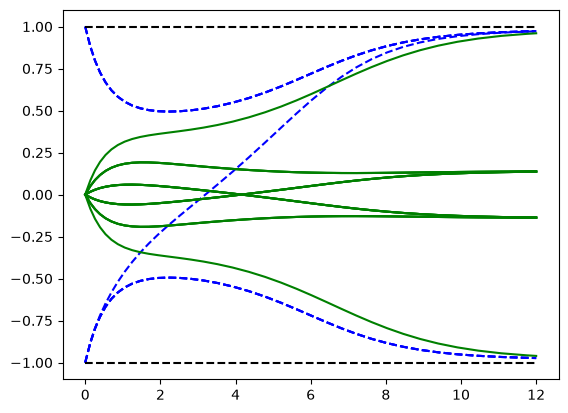

In [33]:
plt.plot(output.t,output.y[0:nFeatures].T,'b--')
plt.plot(output.t,output.y[nFeatures:].T/nFeatures,'g-')
plt.plot(tlimits,[1,1],'k--')
plt.plot(tlimits,[-1,-1],'k--')

(37, 7)
[-0.97300992 -0.97300992 -0.97300992  0.97300992  0.97300992  0.97300992
  0.97174113]


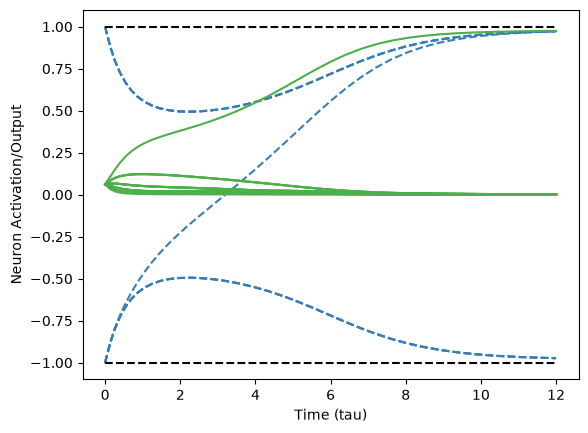

In [37]:
#Transform that into activations rather than internal states
yFeatures = np.copy(output.y[0:nFeatures].T)
for i in range(np.shape(yFeatures)[0]):
    yFeatures[i,:] = f_feature(yFeatures[i,:])
yMemories = np.copy(output.y[nFeatures:].T)
for i in range(np.shape(yMemories)[0]):
    yMemories[i,:] = f_memory(yMemories[i,:])
print(np.shape(yFeatures))
plt.plot(output.t,yFeatures,'--',color='#377EB8')
plt.plot(output.t,yMemories,'-',color='#4DAF4A')
plt.plot(tlimits,[1,1],'k--')
plt.plot(tlimits,[-1,-1],'k--')
plt.xlabel('Time (tau)')
plt.ylabel('Neuron Activation/Output')
print(yFeatures[-1,:])